In [9]:
import pandas as pd
import joblib
import os
from dotenv import load_dotenv
from conformist import FNRCoP, PredictionDataset, ValidationTrial

In [10]:
OUTPUT_DIR = "/home/mariya/Data/pallas/inference/rf_GEX_20260606_190416/fmca-b-other-gex"
# Create the output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [11]:
# Load the model
RF_MODEL_PATH = "/home/mariya/Data/pallas/models/rf_GEX_20260606_190416/rf_model.joblib"
rf = joblib.load(RF_MODEL_PATH)

In [12]:
PREDS_CAL_CSV_PATH = "/home/mariya/Development/pallas/reports/output/predictions/rf_GEX_20260606_190416/cal-gex/cal-gex_predictions.csv"
# Load calibration predictions
preds_cal = pd.read_csv(PREDS_CAL_CSV_PATH, index_col=0)
preds_cal

,true_label,predicted_label,"AML, APL-PML::RARA","AML, CBFA2T3::GLIS2","AML, CBFB::MYH11","AML, CEBPAalt","AML, DEK::NUP214","AML, ETV6-r","AML, FUS::ERG","AML, KAT6A-r",...,"B-ALL, NUTM1-r","B-ALL, PAX5 P80R","B-ALL, PAX5alt","B-ALL, TCF3::PBX1","B-ALL, ZNF384-r","B-ALL, high hyperdiploid","B-ALL, hypodiploid","B-ALL, iAMP21",Non-leukemic,T-ALL
id,,,,,,,,,,,,,,,,,,,,,
SJHBBBM4PX3,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.002879,0.015920,0.015296,0.000329,0.004214,0.003947,0.000000,...,0.004144,0.002882,0.104761,0.014402,0.007580,0.398812,0.078688,0.021828,0.003223,0.028247
SJHBBBN9RDM,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.002225,0.028906,0.006661,0.000000,0.004231,0.000000,0.000000,...,0.000350,0.002574,0.084376,0.006242,0.003626,0.205871,0.050169,0.022101,0.000425,0.048091
817_T,Non-leukemic,Non-leukemic,0.002211,0.000816,0.010066,0.011536,0.000000,0.001957,0.000000,0.000000,...,0.005988,0.015418,0.091809,0.014148,0.013122,0.074932,0.042945,0.017294,0.312856,0.063716
858_T,Non-leukemic,Non-leukemic,0.000379,0.000626,0.011460,0.006613,0.000000,0.001957,0.000000,0.000000,...,0.000284,0.012505,0.086343,0.010093,0.018054,0.061743,0.035041,0.013153,0.345827,0.079644
867_B,Non-leukemic,Non-leukemic,0.000446,0.000111,0.005801,0.009600,0.000000,0.003978,0.001975,0.001960,...,0.002241,0.002734,0.040455,0.017043,0.001688,0.029417,0.024356,0.009618,0.435188,0.026835
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16-328,"B-ALL, DUX4-r","B-ALL, DUX4-r",0.000000,0.000206,0.021329,0.024741,0.000000,0.004160,0.000000,0.001904,...,0.004213,0.000605,0.021508,0.004924,0.003965,0.041773,0.044578,0.005440,0.040131,0.056421
16-335,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000302,0.001288,0.001888,0.000000,0.000000,0.000000,0.000387,...,0.000315,0.000930,0.022216,0.000670,0.005396,0.737348,0.125929,0.026950,0.000494,0.005993
16-338,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000000,0.000000,0.000000,0.000000,0.002000,0.000000,0.000000,...,0.000000,0.000000,0.002019,0.000000,0.000000,0.984834,0.006894,0.000000,0.000000,0.000000


In [13]:
PREDS_TEST_CSV_PATH = "/home/mariya/Data/pallas/inference/rf_GEX_20260606_190416/fmca-b-other-gex/fmca-b-other-gex_predictions.csv"
# Load test predictions
preds_test = pd.read_csv(PREDS_TEST_CSV_PATH, index_col=0)
preds_test

,true_label,predicted_label,"AML, APL-PML::RARA","AML, CBFA2T3::GLIS2","AML, CBFB::MYH11","AML, CEBPAalt","AML, DEK::NUP214","AML, ETV6-r","AML, FUS::ERG","AML, KAT6A-r",...,"B-ALL, NUTM1-r","B-ALL, PAX5 P80R","B-ALL, PAX5alt","B-ALL, TCF3::PBX1","B-ALL, ZNF384-r","B-ALL, high hyperdiploid","B-ALL, hypodiploid","B-ALL, iAMP21",Non-leukemic,T-ALL
id,,,,,,,,,,,,,,,,,,,,,
ALL_1006,"B-ALL, other","B-ALL, high hyperdiploid",0.004588,0.001056,0.005917,0.018515,0.000146,0.002313,0.00000,0.000000,...,0.004431,0.013832,0.074392,0.014830,0.010003,0.404540,0.155234,0.029646,0.006288,0.011744
ALL_219,"B-ALL, other","B-ALL, BCR::ABL1-like",0.000505,0.000762,0.007391,0.011120,0.000000,0.007861,0.00000,0.000000,...,0.004029,0.007123,0.101915,0.012885,0.006376,0.203153,0.078848,0.015312,0.002962,0.017719
ALL_28,"B-ALL, other","B-ALL, high hyperdiploid",0.000379,0.004270,0.010219,0.014959,0.000146,0.014313,0.00000,0.000387,...,0.000758,0.006427,0.152403,0.013600,0.010572,0.239508,0.084315,0.042809,0.014887,0.019665
ALL_477,"B-ALL, other","B-ALL, PAX5alt",0.000379,0.000593,0.006866,0.022493,0.000146,0.006334,0.00000,0.000000,...,0.006255,0.017496,0.208049,0.030735,0.013510,0.147034,0.072176,0.030814,0.014848,0.024047
ALL_514,"B-ALL, other","B-ALL, BCR::ABL1-like",0.000000,0.000148,0.001806,0.009955,0.000000,0.005960,0.00000,0.000387,...,0.000493,0.017911,0.152361,0.007108,0.005984,0.136941,0.036254,0.025581,0.002154,0.012488
ALL_629,"B-ALL, other","B-ALL, BCR::ABL1-like",0.002310,0.000236,0.008546,0.021328,0.000146,0.009980,0.02588,0.001985,...,0.006434,0.037794,0.156497,0.016202,0.010304,0.160557,0.061397,0.029290,0.008306,0.016191
ALL_713,"B-ALL, other","B-ALL, high hyperdiploid",0.000379,0.000236,0.007194,0.017264,0.000146,0.015916,0.02588,0.000387,...,0.005932,0.030709,0.126193,0.006144,0.009280,0.188375,0.063123,0.030407,0.014366,0.020271
ALL_878,"B-ALL, other","B-ALL, PAX5alt",0.000379,0.005005,0.007137,0.019863,0.000146,0.006613,0.00000,0.000000,...,0.010698,0.010450,0.164594,0.024693,0.015616,0.130159,0.099334,0.026816,0.012181,0.027642


In [14]:
# Read in formatted predictions
calpd = PredictionDataset(predictions_csv=PREDS_CAL_CSV_PATH, dataset_name='cal')
testpd = PredictionDataset(predictions_csv=PREDS_TEST_CSV_PATH, dataset_name='test')
calpd, testpd

(<conformist.prediction_dataset.PredictionDataset at 0x7627a31de920>,
 <conformist.prediction_dataset.PredictionDataset at 0x7627a31dc910>)

In [ ]:
# First, check for rare classes in the calibration dataset
class_counts = calpd.df['true_label'].value_counts()
print("Class distribution in calibration data:")
print(class_counts)

# Filter out rare classes (optional)
MIN_SAMPLES = 5  # Minimum samples required per class
rare_classes = class_counts[class_counts < MIN_SAMPLES].index.tolist()
if rare_classes:
    print(f"Warning: Found {len(rare_classes)} classes with fewer than {MIN_SAMPLES} samples: {rare_classes}")
    print("These rare classes may cause numerical issues in conformal prediction")

# Modify alpha to be more conservative when working with small datasets
# Smaller alpha -> larger prediction sets -> more conservative
ALPHA = 0.05  # Try a smaller alpha (was 0.1)

mcp = FNRCoP(calpd, alpha=ALPHA)
mcp.calibrate()

# # Try with more regularization
# mcp = FNRCoP(calpd, alpha=ALPHA)

# # Use try/except to handle potential errors
# try:
#     trial = mcp.do_validation_trial(n_runs=10)
#     trial.run_reports(OUTPUT_DIR)
# except ValueError as e:
#     print(f"Error during conformal calibration: {e}")
#     print("Trying with even more conservative settings...")

#     # Try with even smaller alpha as a fallback
#     mcp = FNRCoP(calpd, alpha=0.01)
#     trial = mcp.do_validation_trial(n_runs=5)  # Fewer runs as a fallback
#     trial.run_reports(OUTPUT_DIR)

Class distribution in calibration data:
true_label
B-ALL, high hyperdiploid    84
AML, KMT2A-r                77
B-ALL, ETV6::RUNX1          69
B-ALL, BCR::ABL1-like       58
AML, RUNX1::RUNX1T1         54
AML, NPM1alt                34
B-ALL, KMT2A-r              33
B-ALL, PAX5alt              33
T-ALL                       26
B-ALL, DUX4-r               26
AML, CBFB::MYH11            25
B-ALL, BCR::ABL1            21
B-ALL, hypodiploid          19
B-ALL, TCF3::PBX1           19
AML, CEBPAalt               17
AML, NUP98-r                14
B-ALL, ZNF384-r             12
B-ALL, ETV6::RUNX1-like     10
B-ALL, MEF2D-r               9
B-ALL, iAMP21                8
AML, DEK::NUP214             7
Non-leukemic                 7
AML, APL-PML::RARA           6
AML, CBFA2T3::GLIS2          6
B-ALL, NUTM1-r               5
B-ALL, PAX5 P80R             5
B-ALL, MYC-r                 5
AML, KAT6A-r                 4
B-ALL, HLF-r                 3
AML, ETV6-r                  3
B-ALL, IKZF1 N159Y 

Saving upset plot to /home/mariya/Data/pallas/inference/rf_GEX_20260606_190416/fmca-b-other-gex/FNRCoP/2026-08-12_11-07-29/upset_plot.pdf


/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

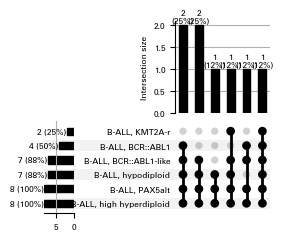

In [16]:
formatted_predictions = mcp.predict(testpd,
                                    OUTPUT_DIR)